# BÀI 03 – TRỰC QUAN DỮ LIỆU GITHUB REPOSITORIES

**Mục tiêu:** Chọn trực quan theo câu hỏi nghiên cứu, nêu rõ vì sao chọn biểu đồ này thay vì biểu đồ khác, và vận dụng Matplotlib trên dữ liệu thật. Các thống kê tính trên giá trị gốc; `log1p` chỉ dùng để nén trục hiển thị.

**Phạm vi dữ liệu:** 12.000 repository trong CSV raw, snapshot `2026-10-26 02:04:57 UTC`. Trong schema không có `watchers_count`; `star_count` và `forks_count` được xem là hai biến riêng, không gộp thành một điểm popularity. Các tệp đã cung cấp cũng chưa có CSV Folder 01 sau imputation.

## 1. Đối chiếu cách phân loại trong slide Bài 03

Slide Bài 03 liệt kê **8 nhóm**: Độ phân bố – Độ trải, Tương quan, So sánh, So sánh với tổng thể, Tiến triển, Bản đồ, Luồng dịch chuyển và Thể hiện khác. Vì slide có tám tên, notebook giữ nguyên cả tám thay vì tự rút gọn thành năm loại biểu đồ.

| Nhóm theo slide | Khái niệm / câu hỏi | Ví dụ phù hợp với dataset | Tính khả thi |
|---|---|---|---|
| Độ phân bố – Độ trải | Giá trị tập trung ở đâu, phân tán thế nào, có đuôi dài/ngoại lệ không? | Phân phối `star_count`, `forks_count`, `size_kb` | Có |
| Tương quan | Hai biến số có biến thiên cùng nhau không? | `star_count` – `forks_count` | Có |
| So sánh | Nhóm/danh mục nào có giá trị lớn hơn? | Tần suất topic hoặc số repo theo ngôn ngữ | Có |
| So sánh với tổng thể | Mỗi thành phần chiếm tỷ lệ bao nhiêu trong toàn bộ? | Cơ cấu `primary_language` | Có, sau khi gộp nhóm nhỏ |
| Tiến triển | Đại lượng thay đổi theo trật tự thời gian thế nào? | Số repo trong mẫu theo `created_year` | Có, nhưng chỉ mô tả mẫu được chọn |
| Bản đồ | Giá trị phân bố theo không gian địa lý | Cần tọa độ/quốc gia/vùng địa lý | Không có biến địa lý |
| Luồng dịch chuyển | Dòng chuyển từ nguồn đến đích | Cần cặp nguồn–đích hoặc chuỗi chuyển trạng thái | Không có biến luồng |
| Thể hiện khác | Nhóm mở cho cách thể hiện đặc thù theo bài toán | Có thể mở rộng nếu xuất hiện dữ liệu cấu trúc khác | Không phải yêu cầu biểu đồ riêng ở dataset hiện tại |

## 2. Bảng so sánh biểu đồ trước khi lựa chọn

### 2.1. Độ phân bố – Độ trải

| Biểu đồ | Thông tin truyền tải | Ưu điểm | Hạn chế | Mức phù hợp với Stars |
|---|---|---|---|---|
| Histogram | Tần suất theo các khoảng giá trị (bins) | Nhìn trực tiếp hình dạng, vùng tập trung và đuôi | Kết quả phụ thuộc bins; không mượt | **Cao – chọn** |
| Violin | Mật độ phân phối theo từng nhóm | So sánh hình dạng nhiều nhóm, thấy đa đỉnh | Khó đọc với người mới; không cho tần suất trực tiếp | Trung bình nếu có nhóm |
| Density / KDE | Ước lượng mật độ liên tục | Dễ nhìn hình dạng, so sánh phân phối | Là ước lượng làm trơn, phụ thuộc bandwidth | Cao để bổ trợ |
| Boxplot | Median, Q1, Q3, IQR và điểm xa | Tóm tắt gọn, nhận diện ngoại lệ | Che khuất cấu trúc nhiều đỉnh | Cao để tóm tắt, không thay histogram |
| Ridgeline | Nhiều mật độ phân phối theo nhóm | So sánh nhiều nhóm trên cùng trục | Dễ rối khi nhiều nhóm; cần biến phân nhóm | Thấp cho một phân phối tổng thể |

**Lựa chọn:** Histogram là biểu đồ chính vì câu hỏi là tần suất `star_count` rơi vào vùng nào. KDE chỉ là đường bổ trợ. Trục dùng `log1p(star_count)` vì dữ liệu lệch phải rất mạnh; số liệu thống kê vẫn tính trên `star_count` gốc.

### 2.2. Tương quan

| Biểu đồ | Mục đích | Ưu điểm | Hạn chế | Khi nên dùng |
|---|---|---|---|---|
| Scatterplot | Hai giá trị số cho từng quan sát | Thấy điểm riêng, xu hướng, ngoại lệ | Chồng lấp điểm khi N lớn | **Cao – chọn cho Stars/Forks** |
| Connected scatter plot | Scatter có nối điểm theo một thứ tự | Thấy đường đi theo thời gian/thứ tự | Nối sai thứ tự gây hiểu nhầm | Chỉ khi có chuỗi thời gian/đường đi |
| Bubble plot | Thêm kích thước bong bóng cho biến thứ ba | Truyền tải ba biến | Diện tích khó so sánh, che điểm | Khi có biến thứ ba đáng kể |
| Heatmap | Giá trị mã hóa bằng màu trên lưới | Tóm tắt ma trận/ô nhóm | Không thể hiện từng repository | Ma trận tương quan hoặc bảng chéo |
| 2D density plot | Mật độ điểm trên mặt phẳng | Giảm chồng lấp | Mất thông tin điểm riêng | Khi mật độ cao |
| Correlogram | Ma trận tương quan nhiều cặp biến | So sánh toàn cục | Không cho thấy dạng phi tuyến/ngoại lệ | Nhiều biến số |

**Lựa chọn:** Scatterplot giữ một điểm cho mỗi repository, phù hợp so sánh Stars–Forks. `log1p` trên hai trục giúp quan sát cả nhóm đông và đuôi cực lớn. Hệ số Pearson/Spearman được tính trên giá trị gốc.

### 2.3. So sánh

| Biểu đồ | Mục đích | Ưu điểm | Hạn chế | Mức phù hợp |
|---|---|---|---|---|
| Horizontal bar | Xếp hạng danh mục theo số lượng | Nhãn dài dễ đọc, so sánh chính xác | Không thể hiện tỷ lệ theo thời gian | **Cao – chọn Top Topics** |
| Vertical bar | So sánh ít danh mục | Quen thuộc | Nhãn dài khó đọc | Trung bình |
| Grouped bar | So sánh nhiều đại lượng giữa nhóm | So sánh nhóm con | Dễ rối khi nhiều nhóm | Khi có nhiều thước đo |
| Stacked bar | Tổng và thành phần trong từng nhóm | Thấy tổng và cấu phần | So sánh phần giữa khó | Khi tổng mỗi nhóm có ý nghĩa |
| Dot / lollipop | Xếp hạng bằng vị trí điểm | Ít mực, dễ đọc | Người xem ít quen hơn | Thích hợp Top Topics |

**Lựa chọn:** Horizontal bar chart cho Top 10 topics vì tên topic dài và mục tiêu là so sánh tần suất chính xác.

### 2.4. So sánh với tổng thể (Part of a Whole)

| Biểu đồ | Mục đích | Ưu điểm | Hạn chế | Khi nên dùng |
|---|---|---|---|---|
| Stacked plot / stacked bar | Thành phần trong từng nhóm hoặc thời điểm | Cho thấy tổng và cơ cấu | Khó so sánh thành phần nhỏ | Nhiều nhóm có tổng rõ |
| Tree plot / treemap | Tỷ trọng bằng diện tích hình chữ nhật | Hiển thị nhiều danh mục | Khó so sánh diện tích gần nhau | Nhiều danh mục |
| Venn diagram | Phần giao giữa các tập | Thấy phần giao đơn giản | Chỉ phù hợp ít tập; không cho tỷ lệ chi tiết | Tập ngôn ngữ/kỹ thuật chồng lấp nếu có tập |
| Doughnut plot | Tỷ trọng các thành phần của tổng | Gọn, dễ nhận ra phần lớn | Góc/diện tích khó so sánh; nhiều lát khó đọc | **Cao sau khi gộp Other – chọn** |
| Pie plot | Tỷ trọng thành phần | Trực quan với ít lát | Nhiều lát nhỏ rất khó so sánh | Ít nhóm |
| Tree diagram | Cấu trúc phân cấp | Cho thấy quan hệ cha–con | Không tối ưu cho tỷ lệ phẳng | Danh mục phân cấp |

**Lựa chọn:** Doughnut cho cơ cấu `primary_language` (loại nhãn `text`, giữ Top 5 và gộp các ngôn ngữ còn lại thành Other). Nếu cần so sánh chính xác các phần nhỏ, bar chart vẫn là lựa chọn tốt hơn.

### 2.5. Tiến triển

| Biểu đồ | Mục đích | Ưu điểm | Hạn chế | Mức phù hợp |
|---|---|---|---|---|
| Line chart | Xu hướng qua các mốc có thứ tự | Nhấn mạnh tăng/giảm và điểm ngoặt | Không phù hợp danh mục không có thứ tự | **Cao – chọn số repo theo năm tạo** |
| Area chart | Nhấn mạnh quy mô tích lũy theo thời gian | Thấy khối lượng | Diện tích có thể phóng đại cảm giác biến động | Trung bình |
| Stacked Area | Cơ cấu nhiều chuỗi thay đổi theo thời gian | Thấy tổng và đóng góp | Khó so sánh lớp giữa | Cần nhiều nhóm theo thời gian |
| Streamgraph | Cơ cấu nhiều nhóm với lớp đối xứng | Hình thức trực quan | Đọc giá trị tuyệt đối khó | Chủ yếu khám phá |
| Timeseries | Chuỗi đo theo thời điểm | Giữ trật tự thời gian | Cần tần suất thời gian có ý nghĩa | Có thể dùng khi có dữ liệu theo tháng/ngày |

**Lựa chọn:** Line chart thể hiện số repository trong mẫu theo năm tạo. Năm 2023 và 2026 không trọn năm; không suy diễn đây là tốc độ tạo repo của toàn GitHub.

## 3. Nạp dữ liệu và chuẩn bị biến dẫn xuất

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_common.py").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "analysis_common.py").is_file():
    raise FileNotFoundError("Không tìm thấy analysis_common.py trong thư mục dự án.")
sys.path.insert(0, str(PROJECT_ROOT))

import json
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from analysis_common import (
    load_raw_data, load_normalized_frames, prepare_analysis_frame,
    get_programming_language_frame, topic_frequency, save_figure,
    NUMERIC_METRICS, POPULARITY_METRICS, PROJECT_ROOT
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

raw = load_raw_data()
df = prepare_analysis_frame(raw)
LANG_DF = get_programming_language_frame(df)
TOPICS = topic_frequency(df)
OUT = PROJECT_ROOT / "outputs" / "bai03"
OUT.mkdir(parents=True, exist_ok=True)

print(f"Số repository: {len(df):,}")
print(f"Số cột raw: {raw.shape[1]}")
print(f"Snapshot UTC: {df['collected_at_dt'].min()}")
print(f"Stars: min={df['star_count'].min():,}; median={df['star_count'].median():,.0f}; mean={df['star_count'].mean():,.1f}; max={df['star_count'].max():,}")
print(f"Không có watchers_count: {'watchers_count' not in df.columns}")
print(f"Số repo dùng cho thống kê ngôn ngữ lập trình (loại Text): {len(LANG_DF):,}")

Số repository: 12,000
Số cột raw: 21
Snapshot UTC: 2026-10-26 02:04:57+00:00
Stars: min=612; median=1,713; mean=4,657.8; max=393,057
Không có watchers_count: True
Số repo dùng cho thống kê ngôn ngữ lập trình (loại Text): 11,042


## 4. Thực hành trực quan theo các câu hỏi của dự án

### 4.1. Độ phân bố – Độ trải: Stars tập trung ở đâu?

**Câu hỏi:** Phân phối Stars của 12.000 repository có cân đối hay lệch mạnh? Histogram cho phép nhìn tần suất theo bins; đường KDE làm mượt để hỗ trợ nhìn hình dạng. Đường Mean/Median trên trục biến đổi chỉ mang mục đích minh họa.

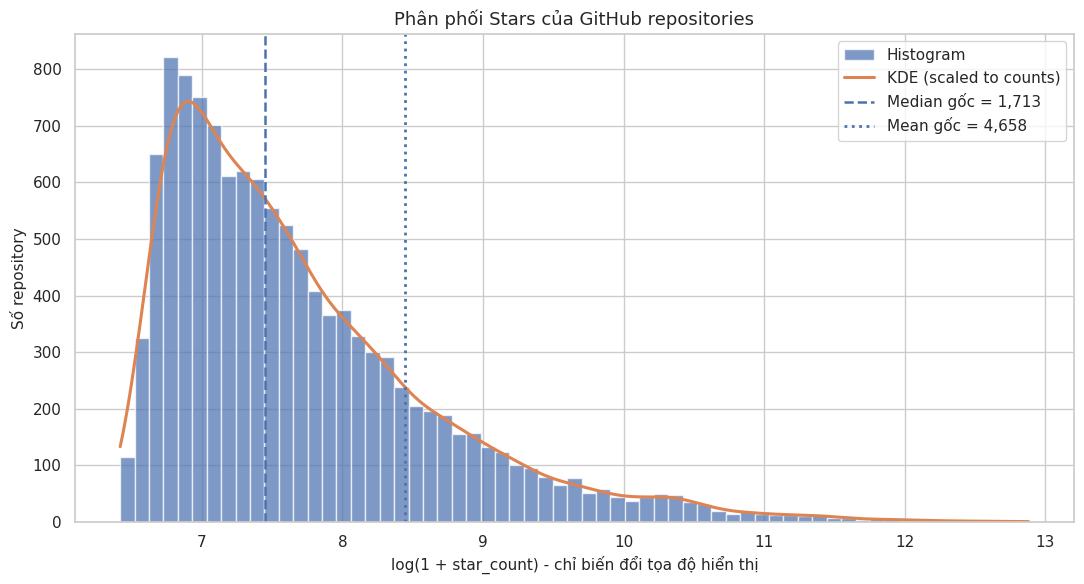

Nhận xét: mean=4,657.8 lớn hơn median=1,713; skewness=12.58. Phân phối lệch phải, đuôi dài.


In [2]:
stars = pd.to_numeric(df["star_count"], errors="coerce").dropna()
log_stars = np.log1p(stars)
bin_edges = np.histogram_bin_edges(log_stars.to_numpy(), bins="fd")
fig, ax = plt.subplots(figsize=(11, 6))
counts, edges, _ = ax.hist(log_stars, bins=bin_edges, alpha=0.72, edgecolor="white", label="Histogram")
try:
    kde = stats.gaussian_kde(log_stars.to_numpy())
    grid = np.linspace(log_stars.min(), log_stars.max(), 400)
    bin_width = float(np.diff(edges).mean())
    ax.plot(grid, kde(grid) * len(log_stars) * bin_width, linewidth=2.2, label="KDE (scaled to counts)")
except Exception as exc:
    print(f"Không vẽ KDE do dữ liệu/ước lượng mật độ: {exc}")
ax.axvline(np.log1p(stars.median()), linestyle="--", linewidth=1.8, label=f"Median gốc = {stars.median():,.0f}")
ax.axvline(np.log1p(stars.mean()), linestyle=":", linewidth=2, label=f"Mean gốc = {stars.mean():,.0f}")
ax.set(title="Phân phối Stars của GitHub repositories", xlabel="log(1 + star_count) - chỉ biến đổi tọa độ hiển thị", ylabel="Số repository")
ax.legend()
fig.tight_layout()
save_figure(fig, OUT / "bai03_histogram_kde_stars.png")
plt.show()
print(f"Nhận xét: mean={stars.mean():,.1f} lớn hơn median={stars.median():,.0f}; skewness={stars.skew():.2f}. Phân phối lệch phải, đuôi dài.")

### 4.2. Tương quan: Stars và Forks có liên hệ ra sao?

**Câu hỏi:** Repository có nhiều Stars thường có nhiều Forks hơn không? Scatterplot thể hiện cặp điểm cho từng repository. Dùng thang `log1p` để giảm chồng lấp ở vùng thấp và nén đuôi phải; đây không phải chuẩn hóa dữ liệu. Tương quan được tính trên số gốc.

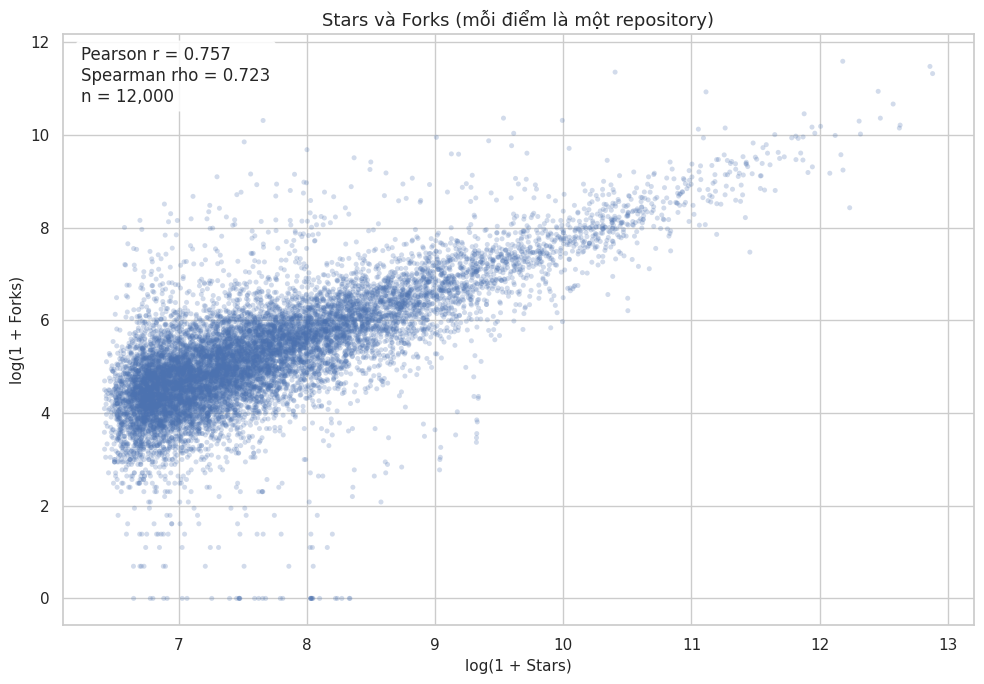

Pearson r=0.7574; Spearman rho=0.7234. Liên hệ dương mạnh, nhưng không chứng minh nhân quả.


In [3]:
corr_df = df[["star_count", "forks_count"]].dropna()
pearson = stats.pearsonr(corr_df["star_count"], corr_df["forks_count"])
spearman = stats.spearmanr(corr_df["star_count"], corr_df["forks_count"])
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(np.log1p(corr_df["star_count"]), np.log1p(corr_df["forks_count"]), s=13, alpha=0.25, edgecolors="none")
ax.set(title="Stars và Forks (mỗi điểm là một repository)", xlabel="log(1 + Stars)", ylabel="log(1 + Forks)")
ax.text(0.02, 0.98, f"Pearson r = {pearson.statistic:.3f}\nSpearman rho = {spearman.statistic:.3f}\nn = {len(corr_df):,}", transform=ax.transAxes, va="top", bbox={"boxstyle":"round", "facecolor":"white", "alpha":0.85})
fig.tight_layout()
save_figure(fig, OUT / "bai03_scatter_stars_forks.png")
plt.show()
print(f"Pearson r={pearson.statistic:.4f}; Spearman rho={spearman.statistic:.4f}. Liên hệ dương mạnh, nhưng không chứng minh nhân quả.")

### 4.3. So sánh: Những topic nào xuất hiện nhiều nhất?

**Câu hỏi:** Các chủ đề nào được gắn nhiều nhất cho repository trong mẫu? Mỗi topic được đếm tối đa một lần trong một repository. Horizontal bar giúp nhãn dài dễ đọc; đây là tần suất xuất hiện, không phải số Stars của chủ đề.

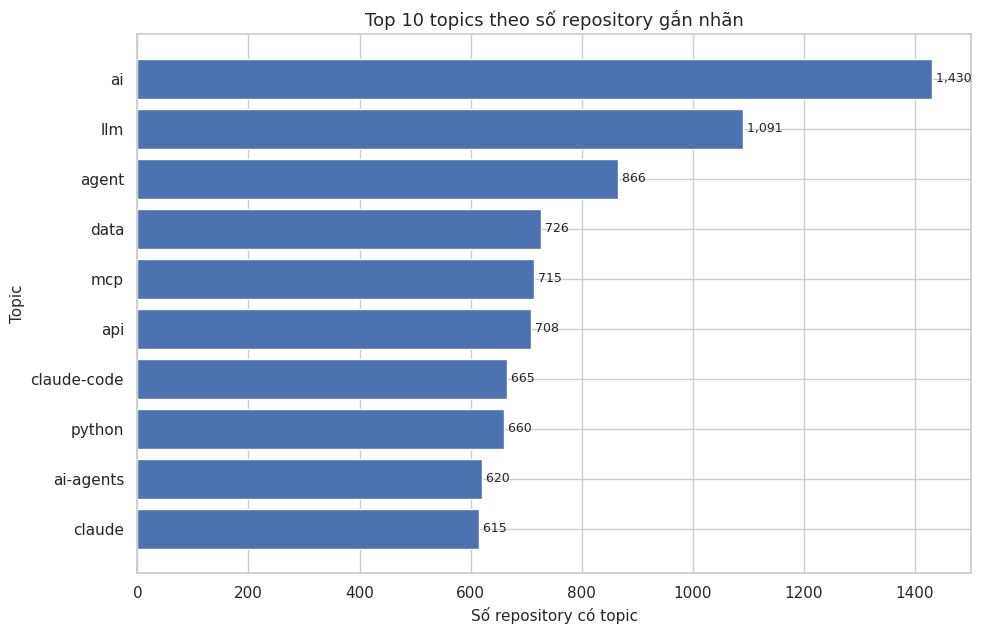

,topic,repository_count,share_of_all_repositories_pct
0,ai,"1,430",11.92%
1,llm,"1,091",9.09%
2,agent,866,7.22%
3,data,726,6.05%
4,mcp,715,5.96%
5,api,708,5.90%
6,claude-code,665,5.54%
7,python,660,5.50%
8,ai-agents,620,5.17%
9,claude,615,5.12%


Có 18,522 topic phân biệt; 131 repository không có topic.


In [4]:
topics_top10 = TOPICS.head(10).sort_values()
topic_table = TOPICS.head(20).rename("repository_count").reset_index().rename(columns={"index":"topic"})
topic_table["share_of_all_repositories_pct"] = topic_table["repository_count"] / len(df) * 100
topic_table.to_csv(PROJECT_ROOT / "results" / "topic_frequency.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(topics_top10.index, topics_top10.values)
ax.set(title="Top 10 topics theo số repository gắn nhãn", xlabel="Số repository có topic", ylabel="Topic")
for y, v in enumerate(topics_top10.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9)
fig.tight_layout()
save_figure(fig, OUT / "bai03_bar_top_topics.png")
plt.show()
display(topic_table.head(10).style.format({"repository_count":"{:,.0f}", "share_of_all_repositories_pct":"{:.2f}%"}))
print(f"Có {len(TOPICS):,} topic phân biệt; {int((df['topic_count']==0).sum()):,} repository không có topic.")

### 4.4. So sánh với tổng thể: Cơ cấu ngôn ngữ lập trình

**Câu hỏi:** Những ngôn ngữ lập trình nào chiếm phần lớn trong mẫu hợp lệ? Doughnut chỉ phù hợp sau khi gom nhóm nhỏ thành Other; nhãn `text` không phải ngôn ngữ lập trình nên được loại khỏi mẫu số.

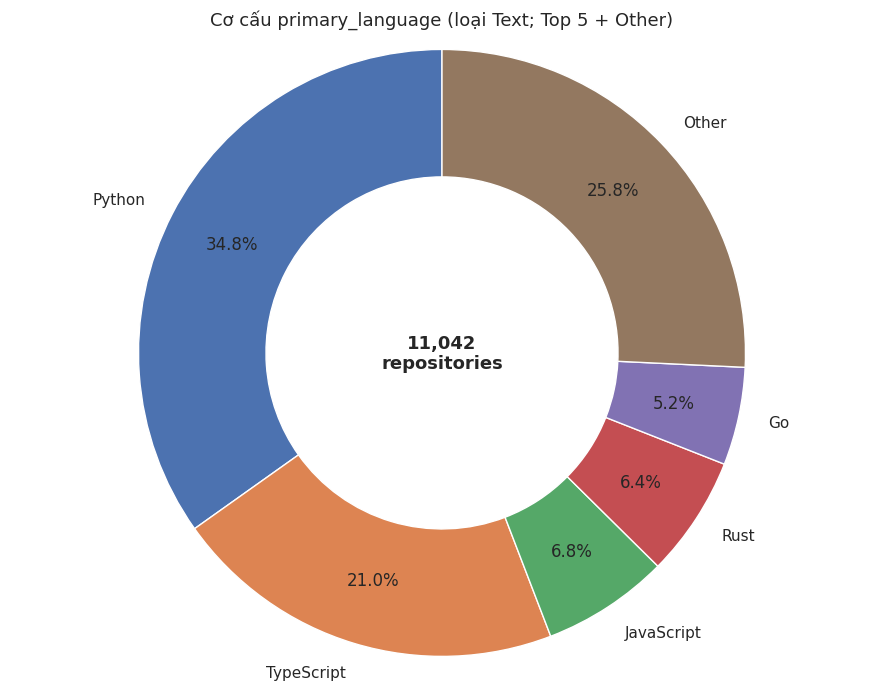

,primary_language,repository_count,share_pct
0,Python,"3,846",34.83%
1,TypeScript,"2,319",21.00%
2,JavaScript,747,6.77%
3,Rust,710,6.43%
4,Go,576,5.22%
5,Other,"2,844",25.76%


Đã loại 958 dòng có primary_language='text'/nhãn rỗng khỏi mẫu số.


In [5]:
lang_counts = LANG_DF["primary_language_clean"].value_counts()
top5 = lang_counts.head(5)
other_count = int(lang_counts.iloc[5:].sum())
labels = top5.index.tolist() + (["Other"] if other_count else [])
values = top5.values.tolist() + ([other_count] if other_count else [])
lang_share = pd.DataFrame({"primary_language": labels, "repository_count": values})
lang_share["share_pct"] = lang_share["repository_count"] / len(LANG_DF) * 100
lang_share.to_csv(PROJECT_ROOT / "results" / "language_share.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(9, 7))
wedges, texts, autotexts = ax.pie(values, labels=labels, autopct="%1.1f%%", startangle=90, pctdistance=0.78, wedgeprops={"width":0.42, "edgecolor":"white"})
ax.set_title("Cơ cấu primary_language (loại Text; Top 5 + Other)")
ax.text(0, 0, f"{len(LANG_DF):,}\nrepositories", ha="center", va="center", fontsize=13, weight="bold")
ax.axis("equal")
fig.tight_layout()
save_figure(fig, OUT / "bai03_doughnut_language.png")
plt.show()
display(lang_share.style.format({"repository_count":"{:,.0f}", "share_pct":"{:.2f}%"}))
print(f"Đã loại {len(df)-len(LANG_DF):,} dòng có primary_language='text'/nhãn rỗng khỏi mẫu số.")

### 4.5. Tiến triển: Số repository trong mẫu theo năm tạo

**Câu hỏi:** Cơ cấu năm tạo của các repository trong mẫu như thế nào? Line chart giữ thứ tự thời gian. Do năm 2023 chỉ có dữ liệu từ tháng 10 và năm 2026 chỉ đến tháng 9, hai năm này là năm chưa trọn vẹn. Mẫu có thể được chọn theo tiêu chí popularity nên không diễn giải là tốc độ tạo repository của toàn GitHub.

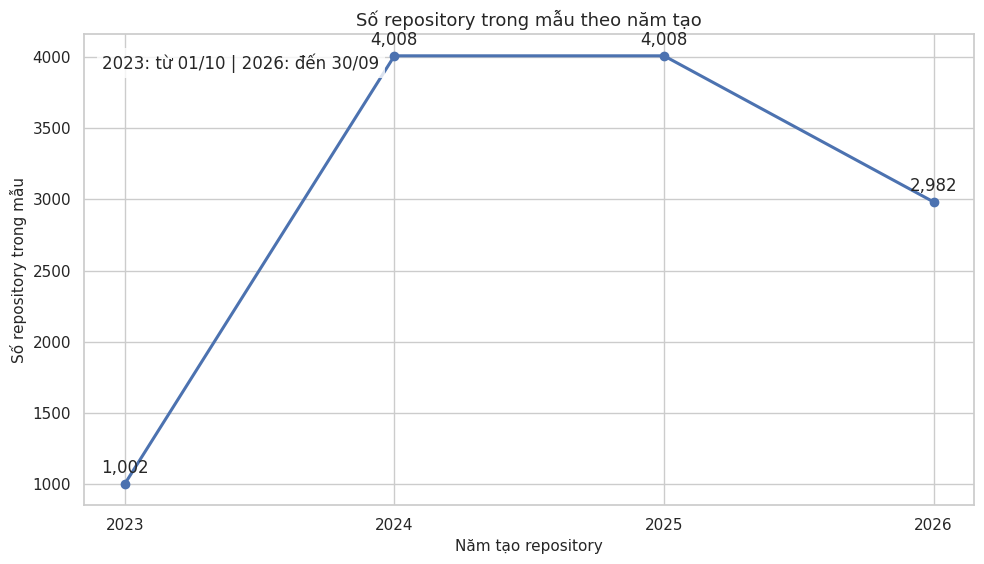

,created_year,repository_count
0,2023,1002
1,2024,4008
2,2025,4008
3,2026,2982


In [6]:
year_counts = df.dropna(subset=["created_year"]).groupby("created_year").size().rename("repository_count").reset_index()
year_counts["created_year"] = year_counts["created_year"].astype(int)
year_counts.to_csv(PROJECT_ROOT / "results" / "repository_counts_by_creation_year.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.plot(year_counts["created_year"], year_counts["repository_count"], marker="o", linewidth=2.2)
for _, row in year_counts.iterrows():
    ax.annotate(f"{int(row.repository_count):,}", (row.created_year, row.repository_count), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set(title="Số repository trong mẫu theo năm tạo", xlabel="Năm tạo repository", ylabel="Số repository trong mẫu", xticks=year_counts["created_year"])
ax.text(0.02, 0.96, "2023: từ 01/10 | 2026: đến 30/09", transform=ax.transAxes, va="top", bbox={"facecolor":"white", "alpha":0.8, "edgecolor":"none"})
fig.tight_layout()
save_figure(fig, OUT / "bai03_line_repositories_by_created_year.png")
plt.show()
display(year_counts)

## 5. Những nhóm không triển khai và lý do

- **Bản đồ:** schema không có tọa độ, quốc gia hoặc khu vực của repository owner. Không thể vẽ bản đồ có căn cứ.
- **Luồng dịch chuyển:** dữ liệu là snapshot trạng thái, không có cặp nguồn–đích hoặc lịch sử chuyển trạng thái.
- **Thể hiện khác:** là nhóm mở; chưa có câu hỏi/dữ liệu đặc thù yêu cầu một biểu đồ riêng.

## 6. Kết luận Bài 03

Histogram phù hợp với Stars lệch phải; scatterplot cho thấy Stars–Forks; horizontal bar xếp hạng topics; doughnut chỉ dùng sau khi gom nhóm; line chart mô tả phân bố năm tạo trong mẫu. Mọi nhận xét chỉ áp dụng cho mẫu 12.000 repository được cung cấp, không suy diễn nguyên nhân và không gộp Stars/Forks/Watchers thành một chỉ số.